### A1: Vanishing point

In [424]:
import cv2 as cv
import matplotlib.pyplot as plt
import numpy as np

### Input image

(np.float64(-0.5), np.float64(655.5), np.float64(799.5), np.float64(-0.5))

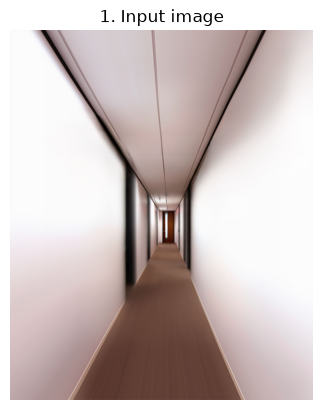

In [425]:
img = cv.imread('./symmetrical.jpg')

scale = min(1.0, 800 / max(img.shape[:2]))
img = cv.resize(
    img, None, fx=scale, fy=scale,
    interpolation=cv.INTER_AREA
)

img_rgb = cv.cvtColor(img, cv.COLOR_BGR2RGB)
img_gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

plt.imshow(img_rgb, cmap='gray')
plt.title("1. Input image")
plt.axis('off')

### Grayscale + histogram equalization

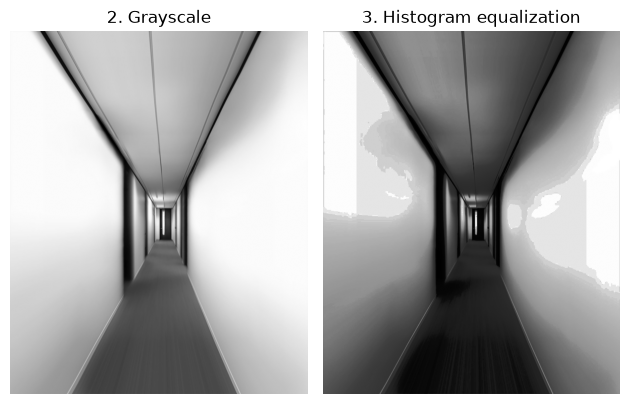

In [426]:
img_gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
equalized = cv.equalizeHist(img_gray)

fig, axes = plt.subplots(1, 2)
axes[0].imshow(img_gray, cmap="gray")
axes[0].set_title("2. Grayscale")
axes[1].imshow(equalized, cmap="gray")
axes[1].set_title("3. Histogram equalization")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

### 45-degree matrix mask

(np.float64(-0.5), np.float64(655.5), np.float64(799.5), np.float64(-0.5))

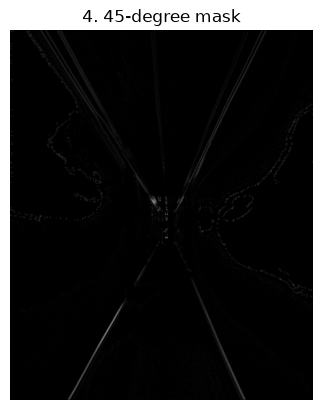

In [427]:
kernel_45 = np.array([
    [-1, -1, 2],
    [-1, 2, -1],
    [2, -1, -1]
], dtype=np.float32)

filtered = cv.filter2D(equalized, ddepth=cv.CV_32F, kernel=kernel_45)

filtered_norm = cv.normalize(np.absolute(filtered), None, alpha=0, beta=255, norm_type=cv.NORM_MINMAX)
filtered_8u = np.uint8(filtered_norm)

plt.imshow(filtered_8u, cmap='gray')
plt.title("4. 45-degree mask")
plt.axis('off')

### Canny

(np.float64(-0.5), np.float64(655.5), np.float64(799.5), np.float64(-0.5))

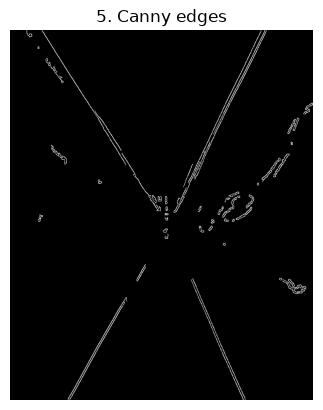

In [428]:
blurred = cv.GaussianBlur(filtered_8u, (5, 5), 0)
edges = cv.Canny(blurred, threshold1=30, threshold2=100)

plt.imshow(edges, cmap='gray')
plt.title("5. Canny edges")
plt.axis('off')

### Hough transform

(np.float64(-0.5), np.float64(655.5), np.float64(799.5), np.float64(-0.5))

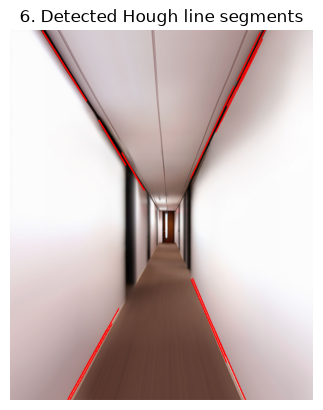

In [429]:
lines = cv.HoughLinesP(
    image=edges,
    rho=1,
    theta=np.pi / 180,
    threshold=60,
    minLineLength=80,
    maxLineGap=5
)

img_lines = img_rgb.copy()

points = []
if lines is not None:
    for line in lines:
        x1, y1, x2, y2 = line
        points.append([x1, y1])
        points.append([x2, y2])
        cv.line(img_lines, (x1, y1), (x2, y2), (255, 0, 0), 2)

plt.imshow(img_lines)
plt.title("6. Detected Hough line segments")
plt.axis('off')

### K-means

(np.float64(-0.5), np.float64(655.5), np.float64(799.5), np.float64(-0.5))

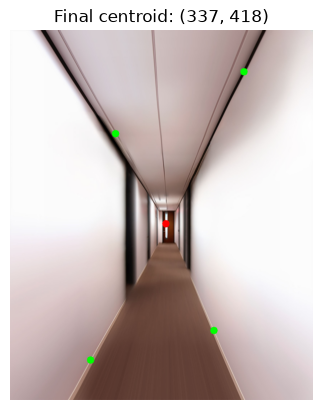

In [430]:
pts = np.float32(points)

criteria = (cv.TERM_CRITERIA_EPS + cv.TERM_CRITERIA_MAX_ITER, 100, 1.0)
ret, label, center = cv.kmeans(
    data=pts, 
    K=4, 
    bestLabels=None, 
    criteria=criteria, 
    attempts=50, 
    flags=cv.KMEANS_PP_CENTERS
)

compactness, labels, vp_centroid = cv.kmeans(
    data=center, 
    K=1, 
    bestLabels=None, 
    criteria=criteria, 
    attempts=50, 
    flags=cv.KMEANS_PP_CENTERS
)

vp_x, vp_y = int(vp_centroid[0][0]), int(vp_centroid[0][1])

output_img = img_rgb.copy()
for pt in center:
    cv.circle(output_img, (int(pt[0]), int(pt[1])), radius=8, color=(0, 255, 0), thickness=-1)

cv.circle(output_img, (vp_x, vp_y), radius=8, color=(255, 0, 0), thickness=-1)

plt.imshow(output_img)
plt.title(f'Final centroid: ({vp_x}, {vp_y})')
plt.axis('off')

### Notes:
The final red dot is located near the far door. In this image,
the selection of resolution and Hough parameters has improved the spatial distribution
of the four centroids. This is the result of a test on a single photograph and is not a guarantee
for every hallway. The center of the image is not used as the target coordinate.

Used the Claude Opus 5.5 model to correct errors.